Loan Approval Prediction using Python

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score,confusion_matrix

Load Dataset

In [2]:
df = pd.read_csv('loan_approval.csv')
df.head()


,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,NaN,Car,Semiurban,Graduate,NaN,Private,No
2,3.0,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,NaN,Urban,NaN,Female,Government,Yes
3,4.0,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,NaN,Graduate,Male,Private,Yes


In [3]:
df = df.drop("Applicant_ID",axis=1)

In [4]:
df.head()

,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,NaN,Car,Semiurban,Graduate,NaN,Private,No
2,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,NaN,Urban,NaN,Female,Government,Yes
3,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,NaN,Graduate,Male,Private,Yes


In [5]:
df.shape

(1000, 19)

In [6]:
df.isnull().sum()

Applicant_Income      50
Coapplicant_Income    50
Employment_Status     50
Age                   50
Marital_Status        50
Dependents            50
Credit_Score          50
Existing_Loans        50
DTI_Ratio             50
Savings               50
Collateral_Value      50
Loan_Amount           50
Loan_Term             50
Loan_Purpose          50
Property_Area         50
Education_Level       50
Gender                50
Employer_Category     50
Loan_Approved         50
dtype: int64

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_Income    950 non-null    float64
 1   Coapplicant_Income  950 non-null    float64
 2   Employment_Status   950 non-null    object 
 3   Age                 950 non-null    float64
 4   Marital_Status      950 non-null    object 
 5   Dependents          950 non-null    float64
 6   Credit_Score        950 non-null    float64
 7   Existing_Loans      950 non-null    float64
 8   DTI_Ratio           950 non-null    float64
 9   Savings             950 non-null    float64
 10  Collateral_Value    950 non-null    float64
 11  Loan_Amount         950 non-null    float64
 12  Loan_Term           950 non-null    float64
 13  Loan_Purpose        950 non-null    object 
 14  Property_Area       950 non-null    object 
 15  Education_Level     950 non-null    object 
 16  Gender 

In [8]:
df.describe()

,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term
count,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000
mean,10852.571579,5082.455789,39.971579,1.474737,676.033684,1.950526,0.347263,9940.452632,24802.792632,20522.825263,48.000000
std,5061.632859,2943.161570,11.139797,1.105067,71.346015,1.406246,0.144341,5860.736885,14345.696031,11504.142575,24.245322
min,2009.000000,1.000000,21.000000,0.000000,550.000000,0.000000,0.100000,65.000000,36.000000,1015.000000,12.000000
25%,6730.750000,2472.750000,30.250000,1.000000,616.250000,1.000000,0.220000,4760.250000,12698.250000,9806.250000,24.000000
50%,10548.000000,5205.500000,40.000000,1.000000,678.000000,2.000000,0.340000,9880.500000,24321.000000,21210.500000,48.000000
75%,15190.000000,7620.750000,49.000000,2.000000,737.000000,3.000000,0.480000,15074.500000,36947.000000,30263.000000,72.000000
max,19988.000000,9996.000000,59.000000,3.000000,799.000000,4.000000,0.600000,19996.000000,49954.000000,39995.000000,84.000000


Handle Missing Values

In [9]:
categorical_col = df.select_dtypes(include=['object']).columns
numerical_col = df.select_dtypes(include=['int64','float64']).columns

In [10]:
categorical_col

Index(['Employment_Status', 'Marital_Status', 'Loan_Purpose', 'Property_Area',
       'Education_Level', 'Gender', 'Employer_Category', 'Loan_Approved'],
      dtype='object')

In [11]:
numerical_col

Index(['Applicant_Income', 'Coapplicant_Income', 'Age', 'Dependents',
       'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings',
       'Collateral_Value', 'Loan_Amount', 'Loan_Term'],
      dtype='object')

In [12]:
from sklearn.impute import SimpleImputer
num_imputer = SimpleImputer(strategy='median')
cat_imputer = SimpleImputer(strategy='most_frequent')

In [13]:
df[numerical_col] = num_imputer.fit_transform(df[numerical_col])
df[categorical_col] = cat_imputer.fit_transform(df[categorical_col])

In [14]:
df.isnull().sum()

Applicant_Income      0
Coapplicant_Income    0
Employment_Status     0
Age                   0
Marital_Status        0
Dependents            0
Credit_Score          0
Existing_Loans        0
DTI_Ratio             0
Savings               0
Collateral_Value      0
Loan_Amount           0
Loan_Term             0
Loan_Purpose          0
Property_Area         0
Education_Level       0
Gender                0
Employer_Category     0
Loan_Approved         0
dtype: int64

Exploratory Data Analysis

In [15]:
df['Loan_Approved'].value_counts()

Loan_Approved
No     702
Yes    298
Name: count, dtype: int64

In [16]:
((df['Loan_Approved'].value_counts(normalize=True) * 100).round(2).astype(str) + "%")

Loan_Approved
No     70.2%
Yes    29.8%
Name: proportion, dtype: object

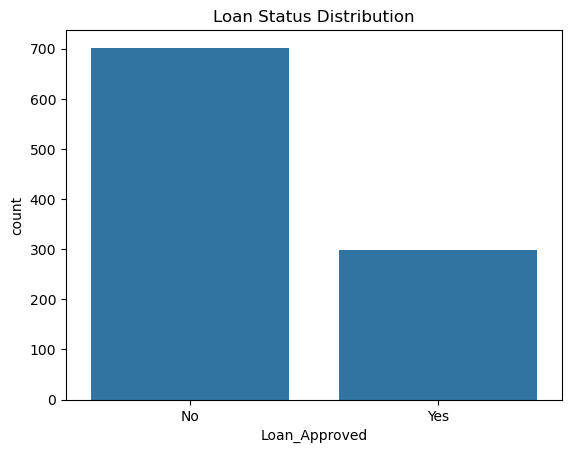

In [17]:
sns.countplot(data=df, x='Loan_Approved')
plt.title("Loan Status Distribution")
plt.show()

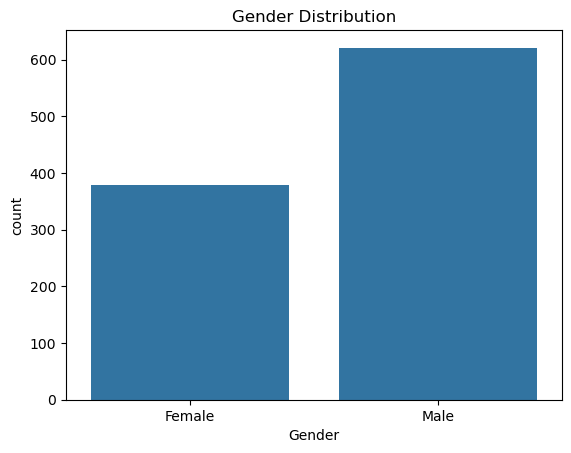

In [18]:
sns.countplot(data=df, x='Gender') 
plt.title("Gender Distribution")
plt.show()

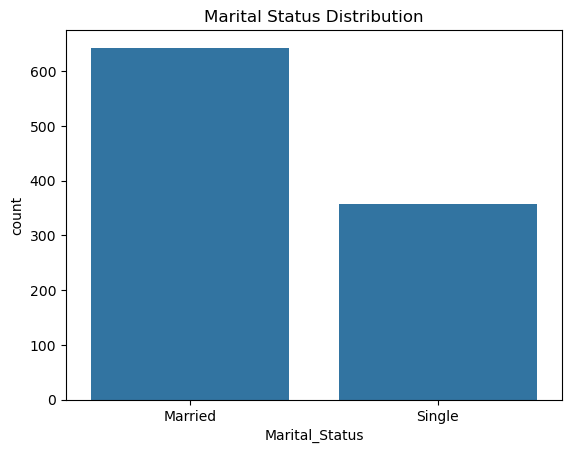

In [19]:
sns.countplot(data=df,x='Marital_Status')
plt.title("Marital Status Distribution")
plt.show()

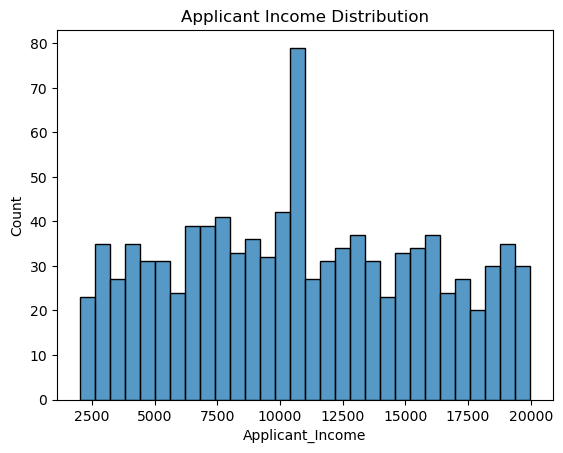

In [20]:
sns.histplot(data=df, x='Applicant_Income', bins=30)
plt.title("Applicant Income Distribution")
plt.show()

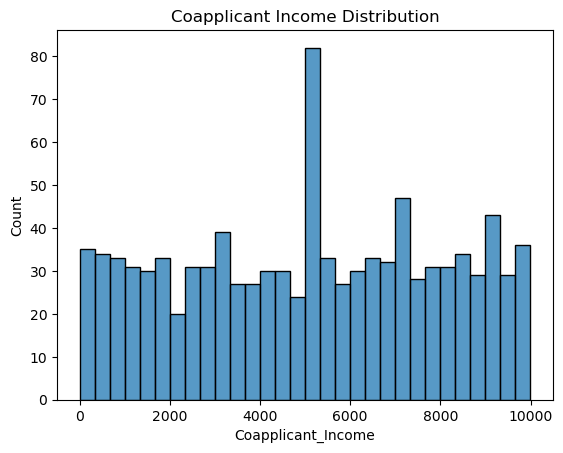

In [21]:
sns.histplot(data=df, x='Coapplicant_Income', bins=30)
plt.title("Coapplicant Income Distribution")
plt.show()

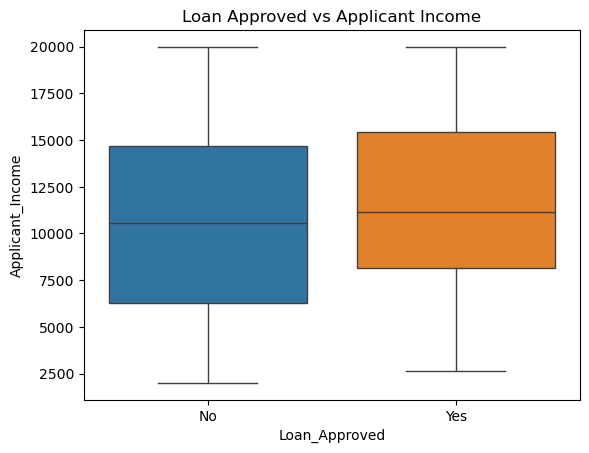

In [23]:
sns.boxplot(data=df, x='Loan_Approved', y='Applicant_Income', hue='Loan_Approved')
plt.title("Loan Approved vs Applicant Income")
plt.show()

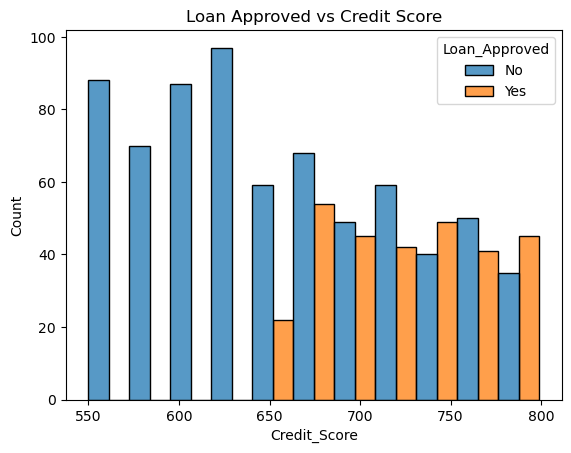

In [24]:
sns.histplot(data=df, x='Credit_Score', hue='Loan_Approved', multiple='dodge')
plt.title("Loan Approved vs Credit Score")
plt.show()

Encoding variables

In [25]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
for col in ['Marital_Status','Gender','Loan_Approved']:
    df[col] = le.fit_transform(df[col])

In [26]:
df.head()

,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,17795.0,1387.0,Salaried,51.0,0,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,0,Private,0
1,2860.0,2679.0,Salaried,46.0,0,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,Graduate,1,Private,0
2,7390.0,2106.0,Salaried,25.0,1,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,Graduate,0,Government,1
3,13964.0,8173.0,Salaried,40.0,0,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,0,Government,0
4,13284.0,4223.0,Self-employed,31.0,1,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,Graduate,1,Private,1


In [27]:
df = pd.get_dummies(df,columns=[
        "Employment_Status",
    "Property_Area",
    "Education_Level",
    "Loan_Purpose",
    "Employer_Category"
],drop_first=True)

In [28]:
df.head()

,Applicant_Income,Coapplicant_Income,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,...,Property_Area_Urban,Education_Level_Not Graduate,Loan_Purpose_Car,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
0,17795.0,1387.0,51.0,0,0.0,637.0,4.0,0.53,19403.0,45638.0,...,True,True,False,False,False,True,False,False,True,False
1,2860.0,2679.0,46.0,0,3.0,621.0,2.0,0.30,2580.0,49272.0,...,False,False,True,False,False,False,False,False,True,False
2,7390.0,2106.0,25.0,1,2.0,674.0,4.0,0.20,13844.0,6908.0,...,True,False,False,False,False,False,True,False,False,False
3,13964.0,8173.0,40.0,0,2.0,579.0,3.0,0.31,9553.0,10844.0,...,False,False,False,False,False,False,True,False,False,False
4,13284.0,4223.0,31.0,1,2.0,721.0,1.0,0.29,9386.0,37629.0,...,True,False,True,False,False,False,False,False,True,False


In [29]:
df.shape

(1000, 28)

In [30]:
df.columns

Index(['Applicant_Income', 'Coapplicant_Income', 'Age', 'Marital_Status',
       'Dependents', 'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings',
       'Collateral_Value', 'Loan_Amount', 'Loan_Term', 'Gender',
       'Loan_Approved', 'Employment_Status_Salaried',
       'Employment_Status_Self-employed', 'Employment_Status_Unemployed',
       'Property_Area_Semiurban', 'Property_Area_Urban',
       'Education_Level_Not Graduate', 'Loan_Purpose_Car',
       'Loan_Purpose_Education', 'Loan_Purpose_Home', 'Loan_Purpose_Personal',
       'Employer_Category_Government', 'Employer_Category_MNC',
       'Employer_Category_Private', 'Employer_Category_Unemployed'],
      dtype='object')

In [31]:
numeric_df = df.select_dtypes(include=['float64','int64'])
corr = numeric_df.corr()['Loan_Approved'].sort_values(ascending=False)
corr

Loan_Approved         1.000000
Credit_Score          0.451235
Applicant_Income      0.120177
Marital_Status        0.030182
Collateral_Value      0.021709
Coapplicant_Income    0.003957
Savings              -0.013462
Dependents           -0.018999
Age                  -0.022354
Existing_Loans       -0.035101
Gender               -0.054342
Loan_Term            -0.086644
Loan_Amount          -0.126608
DTI_Ratio            -0.444766
Name: Loan_Approved, dtype: float64

In [37]:
(corr * 100).round(2)

Loan_Approved         100.00
Credit_Score           45.12
Applicant_Income       12.02
Marital_Status          3.02
Collateral_Value        2.17
Coapplicant_Income      0.40
Savings                -1.35
Dependents             -1.90
Age                    -2.24
Existing_Loans         -3.51
Gender                 -5.43
Loan_Term              -8.66
Loan_Amount           -12.66
DTI_Ratio             -44.48
Name: Loan_Approved, dtype: float64

Training Loan Approval Prediction Model

In [39]:
X = df.drop("Loan_Approved",axis=1)
y = df["Loan_Approved"]

In [40]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

Feature Scaling

In [42]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

In [43]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

models = {
    "Logistic Regression": LogisticRegression(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Naive Bayes": GaussianNB(),
    "KNN": KNeighborsClassifier(),
    "SVM": SVC()
}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    print(f"{name}: {accuracy_score(y_test, y_pred):.4f}")

Logistic Regression: 0.8750
Decision Tree: 0.8750
Random Forest: 0.8800
Naive Bayes: 0.8450
KNN: 0.7300
SVM: 0.8500


In [44]:
from sklearn.metrics import classification_report, confusion_matrix

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    print("="*50)
    print(name)
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred))
    print(confusion_matrix(y_test, y_pred))

Logistic Regression
Accuracy: 0.875
              precision    recall  f1-score   support

           0       0.89      0.94      0.91       139
           1       0.83      0.74      0.78        61

    accuracy                           0.88       200
   macro avg       0.86      0.84      0.85       200
weighted avg       0.87      0.88      0.87       200

[[130   9]
 [ 16  45]]
Decision Tree
Accuracy: 0.875
              precision    recall  f1-score   support

           0       0.91      0.91      0.91       139
           1       0.80      0.79      0.79        61

    accuracy                           0.88       200
   macro avg       0.85      0.85      0.85       200
weighted avg       0.87      0.88      0.87       200

[[127  12]
 [ 13  48]]
Random Forest
Accuracy: 0.88
              precision    recall  f1-score   support

           0       0.91      0.92      0.91       139
           1       0.81      0.79      0.80        61

    accuracy                           0.

Important Features

In [49]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train_scaled, y_train)

feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': rf.feature_importances_
}).sort_values(by='Importance', ascending=False)

print(feature_importance)

                            Feature  Importance
5                      Credit_Score    0.280963
7                         DTI_Ratio    0.269930
0                  Applicant_Income    0.084150
10                      Loan_Amount    0.058453
8                           Savings    0.044771
9                  Collateral_Value    0.043266
1                Coapplicant_Income    0.038780
2                               Age    0.035937
11                        Loan_Term    0.023860
6                    Existing_Loans    0.016488
4                        Dependents    0.014849
13       Employment_Status_Salaried    0.007495
12                           Gender    0.006871
24            Employer_Category_MNC    0.006848
25        Employer_Category_Private    0.006551
19                 Loan_Purpose_Car    0.006235
17              Property_Area_Urban    0.006151
3                    Marital_Status    0.006076
23     Employer_Category_Government    0.005959
18     Education_Level_Not Graduate    0

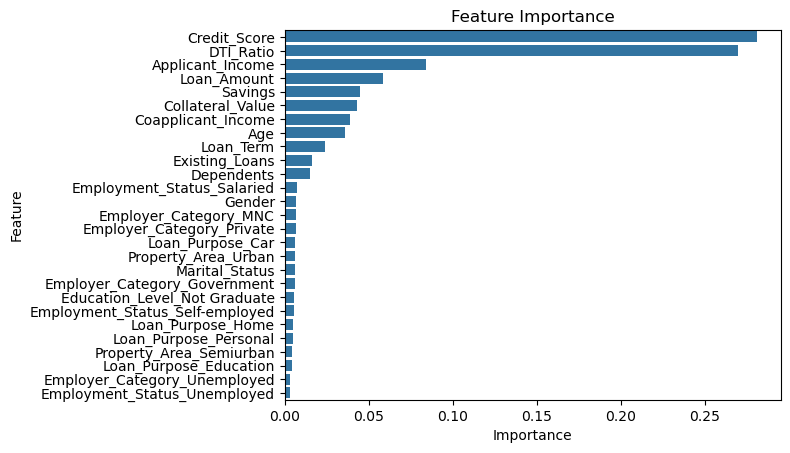

In [50]:
sns.barplot(data=feature_importance, x='Importance', y='Feature')
plt.title("Feature Importance")
plt.show()

In [51]:
import joblib

joblib.dump(rf, "random_forest_model.pkl")
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']